# Exploratory Data Analysis

In [ ]:
%matplotlib inline

In [3]:
# Ignore deprecated warning
import warnings

warnings.filterwarnings("ignore")
import pandas as pd
from pandas import DataFrame
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams.update({'font.size': 18})

print("\033[1mLOAD DATA\033[0m.")
data= pd.read_csv('HappinessSurvey2020.csv') 
print('Data size',data.shape)
data.head()

LOAD DATA.
Data size (126, 7)


,Y,X1,X2,X3,X4,X5,X6
0,0,3,3,3,4,2,4
1,0,3,2,3,5,4,3
2,1,5,3,3,3,3,5
3,0,5,4,3,3,3,5
4,0,5,4,3,3,3,5


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Y       126 non-null    int64
 1   X1      126 non-null    int64
 2   X2      126 non-null    int64
 3   X3      126 non-null    int64
 4   X4      126 non-null    int64
 5   X5      126 non-null    int64
 6   X6      126 non-null    int64
dtypes: int64(7)
memory usage: 7.0 KB


# Class distribution

In [7]:
label_pct = data['Y'].value_counts(normalize = True)*100
label_ct =  data['Y'].value_counts()
pd.DataFrame({'labels': label_pct.index, 'count': label_ct.values, 'percentage': label_pct.values})

,labels,count,percentage
0,1,69,54.761905
1,0,57,45.238095


# Descriptive statistics

In [10]:
data.drop('Y', axis =1).describe()

,X1,X2,X3,X4,X5,X6
count,126.000000,126.000000,126.000000,126.000000,126.000000,126.000000
mean,4.333333,2.531746,3.309524,3.746032,3.650794,4.253968
std,0.800000,1.114892,1.023440,0.875776,1.147641,0.809311
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,4.000000,2.000000,3.000000,3.000000,3.000000,4.000000
50%,5.000000,3.000000,3.000000,4.000000,4.000000,4.000000
75%,5.000000,3.000000,4.000000,4.000000,4.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [46]:


features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6']

# Store all crosstabs in a dictionary
crosstabs = {col: pd.crosstab(data[col], data['Y']) for col in features}

# Access and display each table
for col, table in crosstabs.items():
    print(f"--- {col} vs y ---")
    print(table)


--- X1 vs y ---
Y    0   1
X1        
1    1   0
3   12   8
4   24  16
5   20  45
--- X2 vs y ---
Y    0   1
X2        
1   13  14
2   13  21
3   19  23
4   10   7
5    2   4
--- X3 vs y ---
Y    0   1
X3        
1    4   3
2    7   7
3   29  26
4   11  22
5    6  11
--- X4 vs y ---
Y    0   1
X4        
1    0   2
2    4   1
3   20  21
4   23  30
5   10  15
--- X5 vs y ---
Y    0   1
X5        
1    5   2
2    9   7
3   12  10
4   22  28
5    9  22
--- X6 vs y ---
Y    0   1
X6        
1    0   1
2    1   0
3   14   6
4   20  27
5   22  35


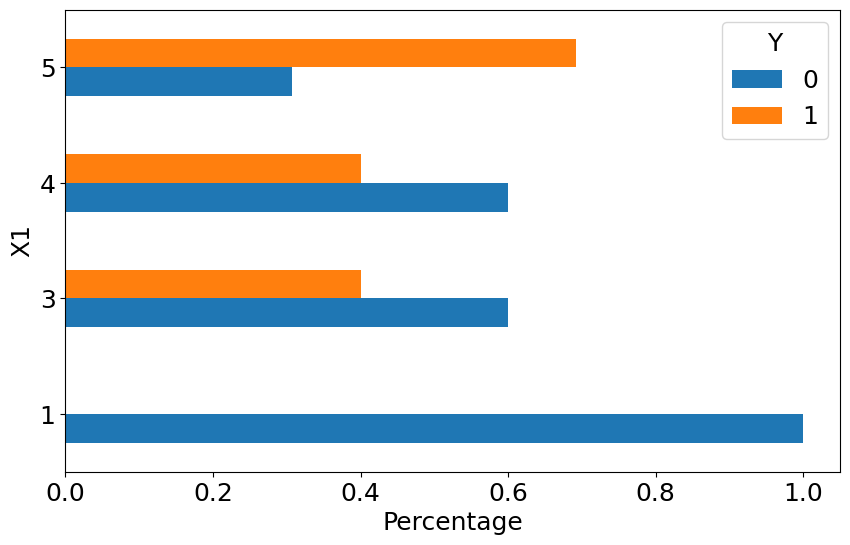

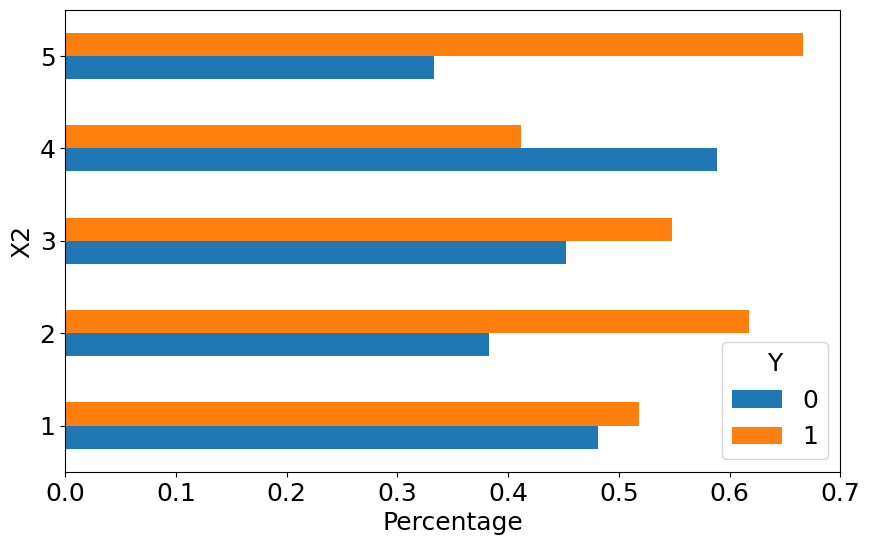

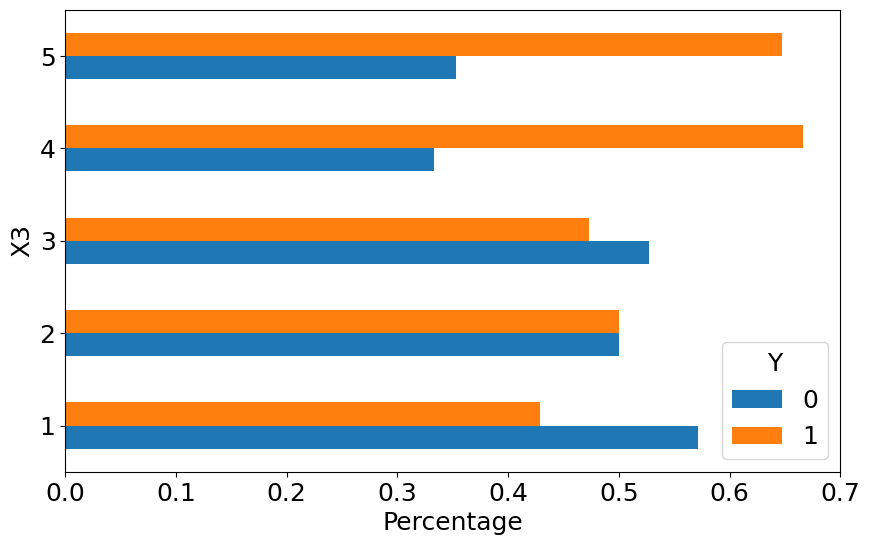

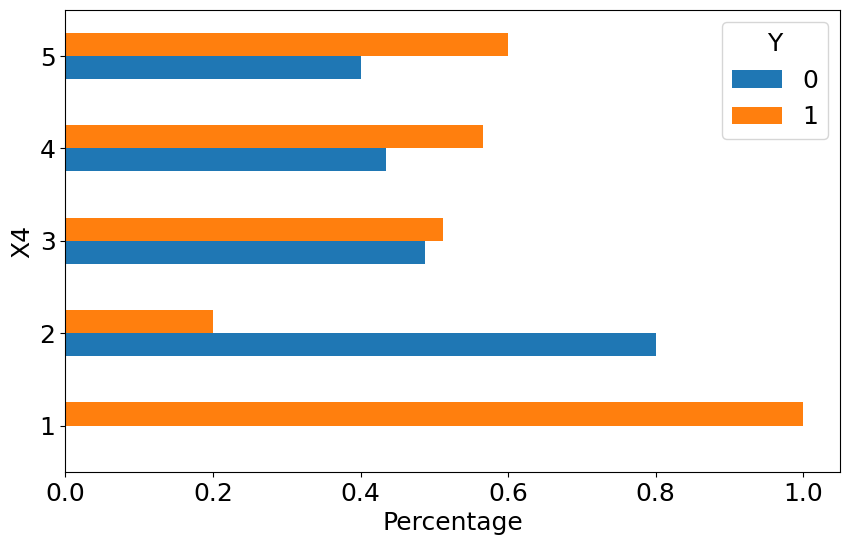

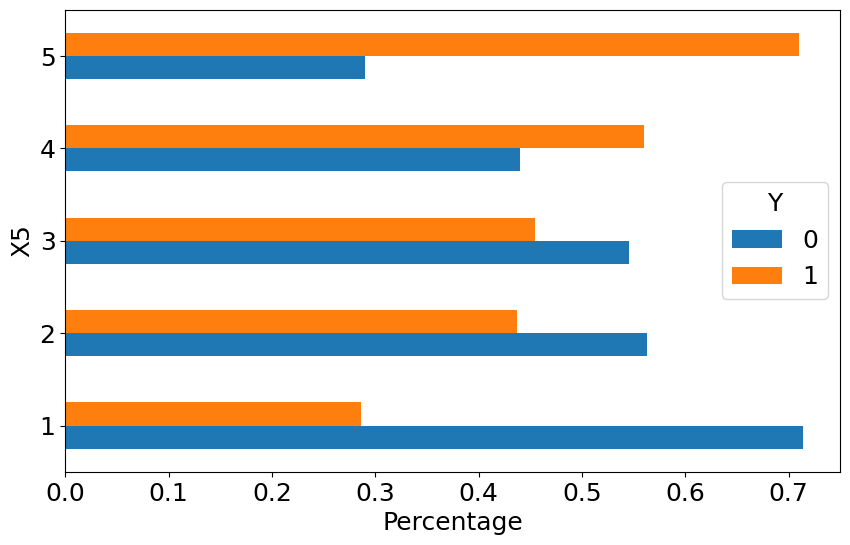

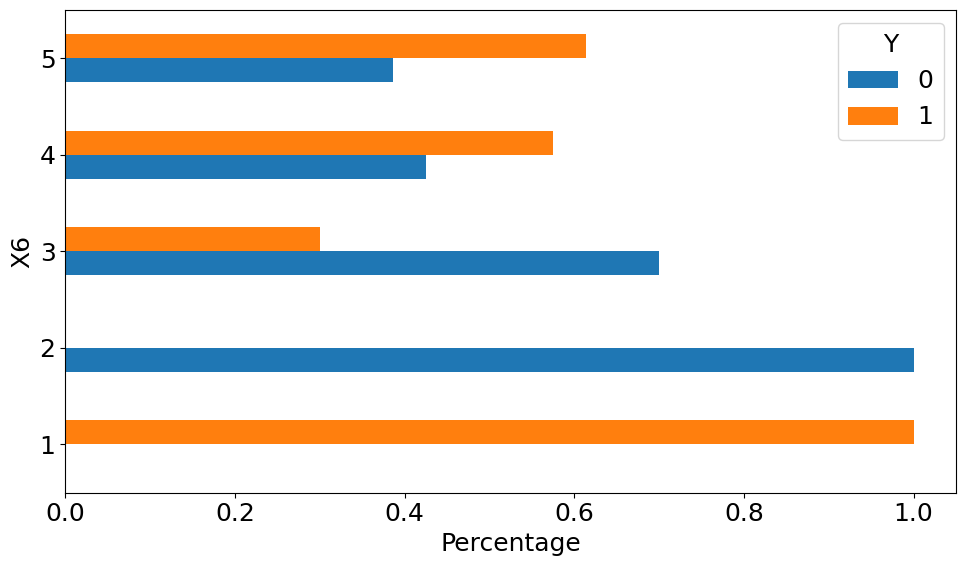

In [43]:
X1  = data["X1"]
X2  = data["X2"]
X3  = data["X3"]
X4  = data["X4"]
X5  = data["X5"]
X6  = data["X6"]

x_data = [X1, X2, X3, X4, X5, X6]
#  Loop through your data and plot each one individually
for i in range(6):
    pvt = pd.crosstab(index = x_data[i], columns = data['Y'], normalize= 'index')
    pvt.plot(kind = 'barh', stacked = False, figsize = (10,6))
    plt.xlabel('Percentage')
plt.tight_layout()
plt.show()



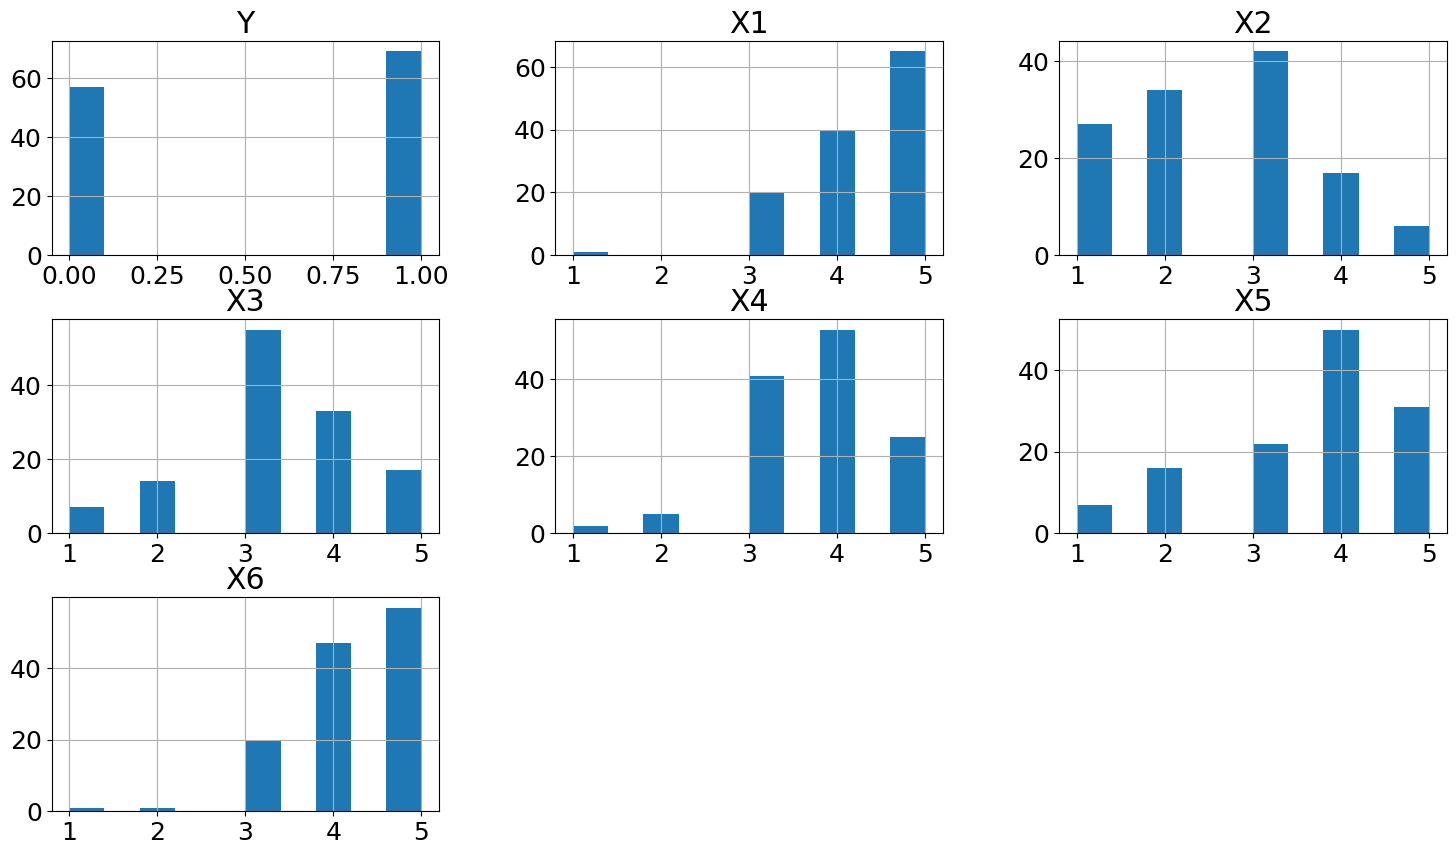

In [32]:

cols = list(data.select_dtypes('number'))
data[cols].hist(figsize = (18,10))
plt.show()



 Balanced Supervised Machine Learning

    In this notebook, I have trained the following supervised ML models:

    Logistic Regression

    Random Forest

 

In [66]:
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from sklearn.svm import SVC
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 15})
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, PrecisionRecallDisplay, roc_curve, auc, classification_report
# Import custom classes
%run -i "./src/helper/01_transfxn.py"
%run -i "./src/helper/02_ml.py"
# Instantiate the classes
transfxn = TransformationPipeline()
model = SupervisedModels()

<Figure size 640x480 with 0 Axes>

# CREATE TEST SET 
We now split the data set into training set and test set in a stratify fashion 

# LOAD DATA and Split X and y 



In [67]:
data= pd.read_csv('HappinessSurvey2020.csv') 
print('Data size',data.shape)
data.head()
# split X and Y ============================ 
X = data.drop(columns=['Y'])
y= data['Y']
X1  = data[["X1"]]
X2  = data[["X2"]]
X3  = data[["X3"]]
X4  = data[["X4"]]
X5  = data[["X5"]]
X6  = data[["X6"]]

# Plot X, Y=======================================================
# Put the X data into a list for easy looping
x_data = [X1, X2, X3, X4, X5, X6]

Data size (126, 7)


In [68]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, 
                                                    stratify=y)

In [69]:
print(f'Training set size: {X_train.shape, y_train.shape}')
print(f'Test set size: {X_test.shape, y_test.shape}')

Training set size: ((100, 6), (100,))
Test set size: ((26, 6), (26,))


In [70]:
print(f'Training set class distribution:\n {(y_train.value_counts()/X_train.shape[0])*100}')
print('--' * 15)
print(f'Test set class distribution:\n {(y_test.value_counts()/X_test.shape[0])*100}')

Training set class distribution:
 Y
1    55.0
0    45.0
Name: count, dtype: float64
------------------------------
Test set class distribution:
 Y
1    53.846154
0    46.153846
Name: count, dtype: float64


# Model Training

    Section A-1. Logistic Regression

In [71]:
log_clf = LogisticRegression(random_state=42)  
log_clf.fit(X_train, y_train)

# Prediction on the training set
model.prediction(log_clf, X_train, y_train, 
                 subset='training set',
                 model_nm='Logistic Regression',
                )

Predictions on the training set for Logistic Regression
------------------------------------------------------------
Accuracy:  0.570000
AUC-ROC: 0.663636
AUC-PR: 0.733743
Predicted classes: [0 1]
Confusion matrix:
 [[18 27]
 [16 39]]
Classification report:
               precision    recall  f1-score   support

           0       0.53      0.40      0.46        45
           1       0.59      0.71      0.64        55

    accuracy                           0.57       100
   macro avg       0.56      0.55      0.55       100
weighted avg       0.56      0.57      0.56       100

------------------------------------------------------------


In [72]:
# Prediction on the test set
model.prediction(log_clf, X_test, y_test, 
                 subset='training set',
                 model_nm='Logistic Regression',
                )

Predictions on the training set for Logistic Regression
------------------------------------------------------------
Accuracy:  0.615385
AUC-ROC: 0.738095
AUC-PR: 0.805147
Predicted classes: [0 1]
Confusion matrix:
 [[ 4  8]
 [ 2 12]]
Classification report:
               precision    recall  f1-score   support

           0       0.67      0.33      0.44        12
           1       0.60      0.86      0.71        14

    accuracy                           0.62        26
   macro avg       0.63      0.60      0.58        26
weighted avg       0.63      0.62      0.59        26

------------------------------------------------------------


    Section B-1. Random Forest


In [73]:
rf_clf = RandomForestClassifier(random_state=42)   
rf_clf.fit(X_train, y_train)

# Prediction on the training set
model.prediction(rf_clf, X_train, y_train, 
                 subset='training set',
                 model_nm='Random Forest Classifier',
                )

Predictions on the training set for Random Forest Classifier
------------------------------------------------------------
Accuracy:  0.960000
AUC-ROC: 0.996162
AUC-PR: 0.996107
Predicted classes: [0 1]
Confusion matrix:
 [[41  4]
 [ 0 55]]
Classification report:
               precision    recall  f1-score   support

           0       1.00      0.91      0.95        45
           1       0.93      1.00      0.96        55

    accuracy                           0.96       100
   macro avg       0.97      0.96      0.96       100
weighted avg       0.96      0.96      0.96       100

------------------------------------------------------------


In [75]:


# Prediction on the TEST set
model.prediction(rf_clf, X_test, y_test, 
                 subset='training set',
                 model_nm='Random Forest Classifier',
                )

Predictions on the training set for Random Forest Classifier
------------------------------------------------------------
Accuracy:  0.653846
AUC-ROC: 0.672619
AUC-PR: 0.754370
Predicted classes: [0 1]
Confusion matrix:
 [[9 3]
 [6 8]]
Classification report:
               precision    recall  f1-score   support

           0       0.60      0.75      0.67        12
           1       0.73      0.57      0.64        14

    accuracy                           0.65        26
   macro avg       0.66      0.66      0.65        26
weighted avg       0.67      0.65      0.65        26

------------------------------------------------------------


 Section B-3 Cumputing the most important features

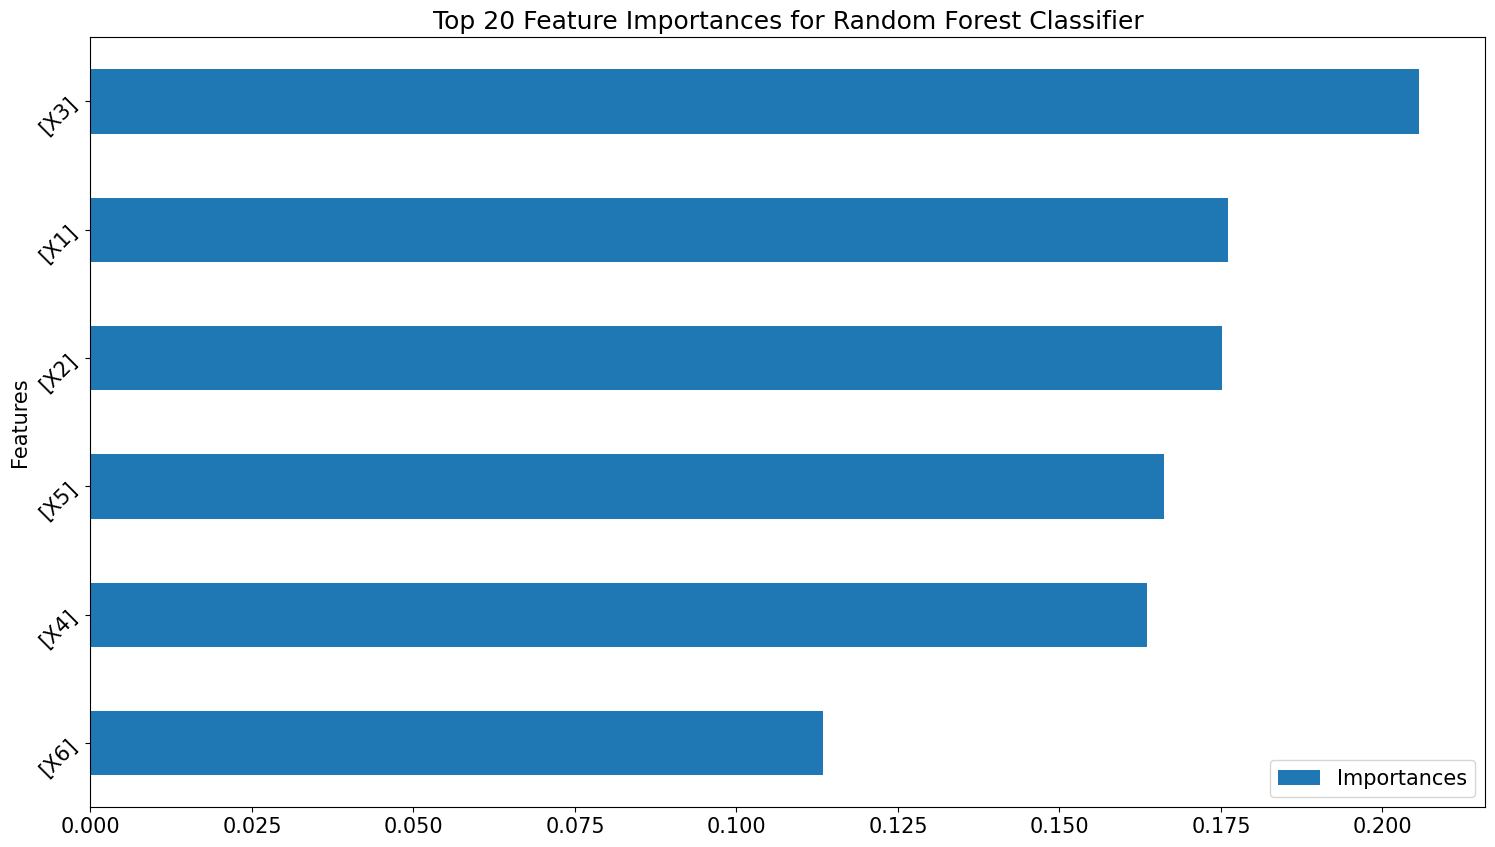

In [76]:
# Compute feature importances
importances_df = pd.DataFrame(
    {
        'Features': x_data, 
        'Importances': rf_clf.feature_importances_,
    }
)
# Bar plot
importances_df.sort_values('Importances', ascending=True, inplace=True)
importances_df.set_index('Features', inplace=True)
importances_df.tail(20).plot(kind='barh', figsize=(18,10))
plt.yticks(rotation=45)
plt.title('Top 20 Feature Importances for Random Forest Classifier')
plt.show()

  Section B-4 Selecting the most imortant features and retraining both Logistic and Random Forest

In [81]:
X_selected = X.drop(columns=['X3', 'X6'])

X_train_selected, X_test_selected, y_train_selected, y_test_selected = train_test_split(X_selected , y, test_size=0.2,
                                                    random_state=42, 
                                                   stratify=y)

In [82]:
#Retrain final model ONLY on important features 
rf_clf.fit(X_train_selected, y_train_selected)
log_clf.fit(X_train_selected, y_train_selected)

# Prediction on the training set
model.prediction(log_clf, X_test_selected, y_test_selected, 
                 subset='training set',
                 model_nm='Logistic Regression',
                )

model.prediction(rf_clf, X_test_selected, y_test_selected, 
                 subset='training set',
                 model_nm='Random Forest Classifier',
                )


Predictions on the training set for Logistic Regression
------------------------------------------------------------
Accuracy:  0.615385
AUC-ROC: 0.755952
AUC-PR: 0.808993
Predicted classes: [0 1]
Confusion matrix:
 [[ 4  8]
 [ 2 12]]
Classification report:
               precision    recall  f1-score   support

           0       0.67      0.33      0.44        12
           1       0.60      0.86      0.71        14

    accuracy                           0.62        26
   macro avg       0.63      0.60      0.58        26
weighted avg       0.63      0.62      0.59        26

------------------------------------------------------------
Predictions on the training set for Random Forest Classifier
------------------------------------------------------------
Accuracy:  0.846154
AUC-ROC: 0.857143
AUC-PR: 0.906067
Predicted classes: [0 1]
Confusion matrix:
 [[11  1]
 [ 3 11]]
Classification report:
               precision    recall  f1-score   support

           0       0.79      0.92 

In [47]:
# Load trained model
log_clf = joblib.load('./src/model/log_clf.pkl')
rf_clf = joblib.load('./src/model/rf_clf.pkl')


    Section C. ROC and PR Curves

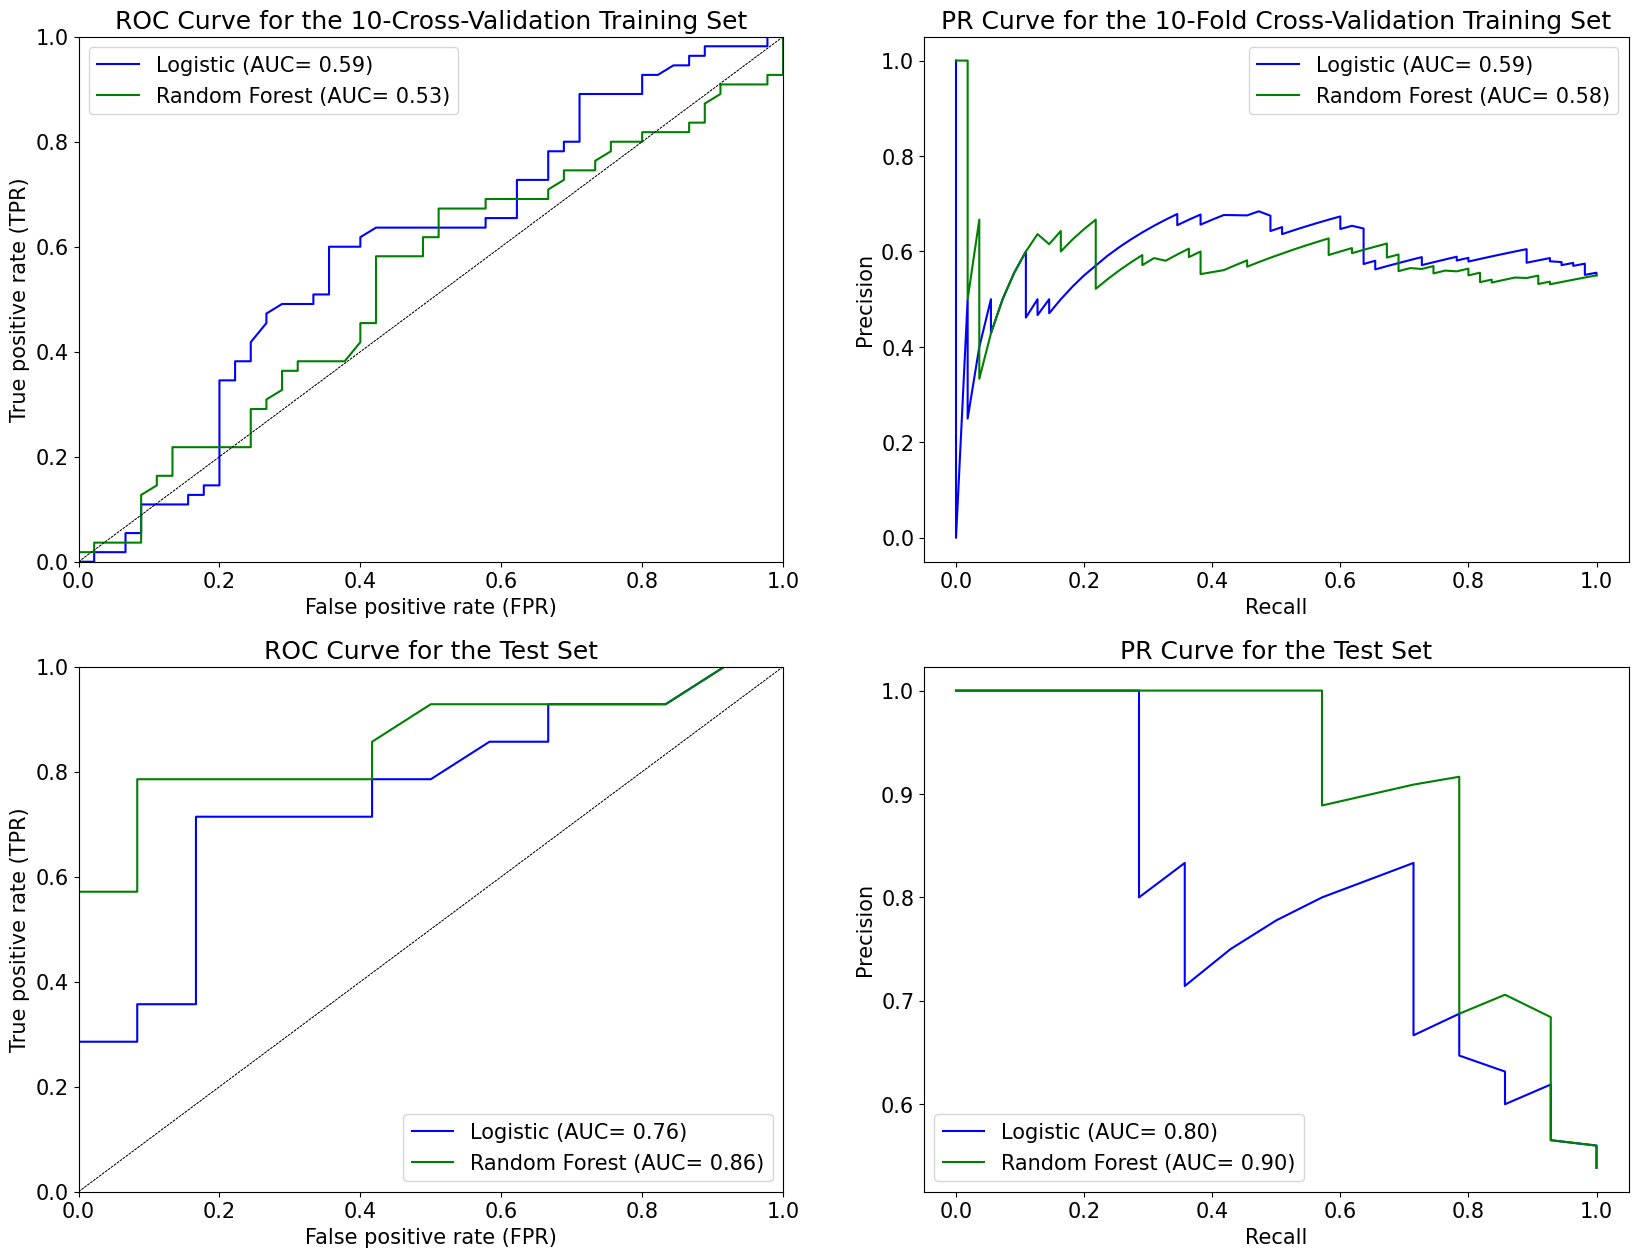

In [83]:

plt.figure(figsize=(20,15))

# Logistic
log_clf.fit(X_train_selected, y_train_selected)
model.plot_roc_pr_curves(log_clf, X_train_selected, y_train_selected, X_test_selected, y_test_selected, 
                         cv_fold=10, color='b', label='Logistic (AUC= %0.2f)',
                        )

# Random Forest
rf_clf.fit(X_train_selected, y_train_selected)
model.plot_roc_pr_curves(rf_clf, X_train_selected, y_train_selected, X_test_selected, y_test_selected, 
                         cv_fold=10, color='g', label='Random Forest (AUC= %0.2f)',
                        )
